<a href="https://colab.research.google.com/github/YUCAVALCANTE/DATAVIZ_MATPLOTLIB/blob/main/Netflix_recomenda%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Recommendations for the user:

1. Movie A | Similarity: 0.9979 | Ângulo: 3.7°
2. Movie D | Similarity: 0.9886 | Ângulo: 8.7°
3. Movie C | Similarity: 0.8127 | Ângulo: 35.6°
4. Movie B | Similarity: 0.6644 | Ângulo: 48.4°
5. Movie E | Similarity: 0.5154 | Ângulo: 59.0°


/tmp/ipykernel_6174/3359584282.py:53: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("RdYlGn") if hasattr(cm, "get_cmap") else plt.get_cmap("RdYlGn")


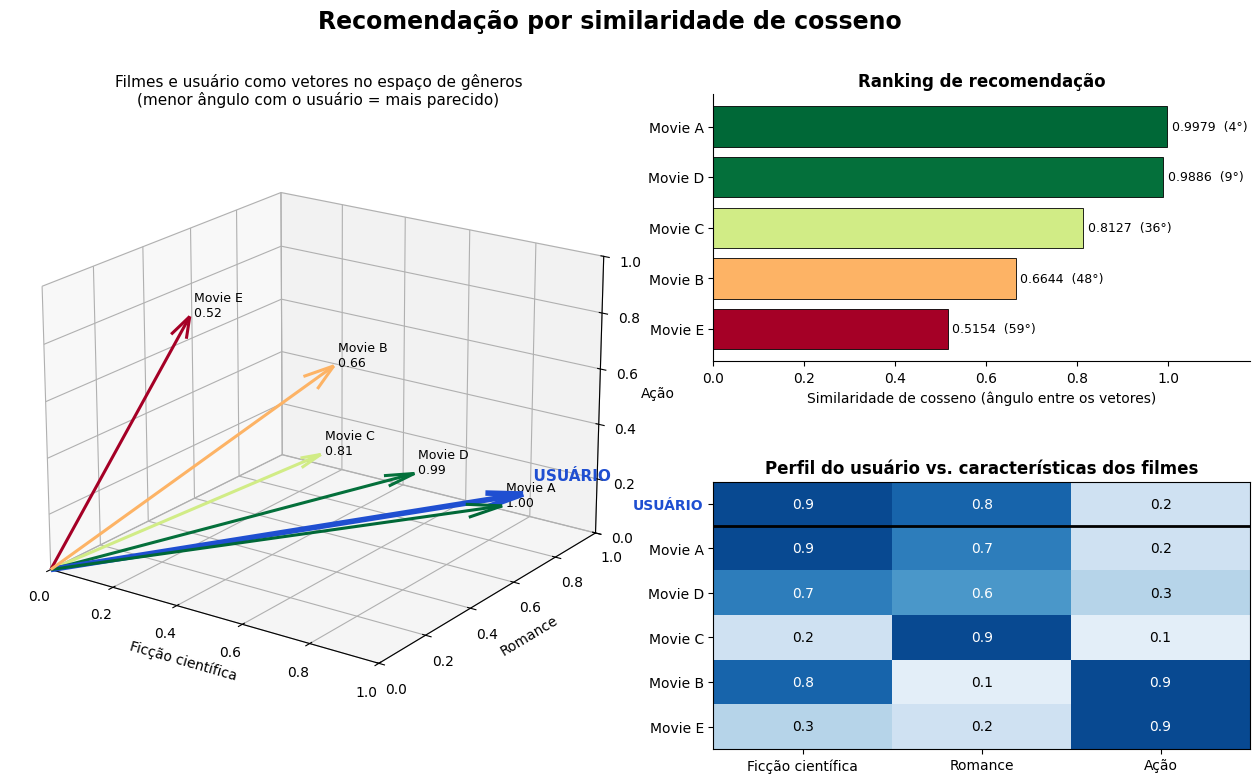

In [2]:
from math import sqrt, acos, degrees

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

# Dimensions:
# [science fiction, romance, action]
dimensions = ["Ficção científica", "Romance", "Ação"]

movies = {
    "Movie A": [0.9, 0.7, 0.2],
    "Movie B": [0.8, 0.1, 0.9],
    "Movie C": [0.2, 0.9, 0.1],
    "Movie D": [0.7, 0.6, 0.3],
    "Movie E": [0.3, 0.2, 0.9],
}

user_profile = [0.9, 0.8, 0.2]


def cosine_similarity(vector_a, vector_b):
    if len(vector_a) != len(vector_b):
        raise ValueError("Vectors must have the same dimension.")

    dot_product = sum(a * b for a, b in zip(vector_a, vector_b))
    norm_a = sqrt(sum(a ** 2 for a in vector_a))
    norm_b = sqrt(sum(b ** 2 for b in vector_b))

    if norm_a == 0 or norm_b == 0:
        return 0.0

    return dot_product / (norm_a * norm_b)


# ---------- Cálculo (igual ao original) ----------
recommendations = []
for title, features in movies.items():
    score = cosine_similarity(user_profile, features)
    recommendations.append((title, score))

recommendations.sort(key=lambda item: item[1], reverse=True)

print("Recommendations for the user:\n")
for position, (title, score) in enumerate(recommendations, start=1):
    angle = degrees(acos(min(1.0, score)))
    print(f"{position}. {title} | Similarity: {score:.4f} | Ângulo: {angle:.1f}°")


# ---------- Visualização ----------
scores = dict(recommendations)
norm = Normalize(vmin=min(scores.values()), vmax=max(scores.values()))
cmap = cm.get_cmap("RdYlGn") if hasattr(cm, "get_cmap") else plt.get_cmap("RdYlGn")
color_of = {title: cmap(norm(s)) for title, s in scores.items()}
USER_COLOR = "#1f4fd1"

fig = plt.figure(figsize=(16, 8.5))
fig.suptitle(
    "Recomendação por similaridade de cosseno",
    fontsize=17, fontweight="bold",
)
grid = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], height_ratios=[1, 1],
                        hspace=0.45, wspace=0.15)

# 1) Vetores em 3D: quanto menor o ângulo com o usuário, mais parecido
ax3d = fig.add_subplot(grid[:, 0], projection="3d")
ax3d.set_title("Filmes e usuário como vetores no espaço de gêneros\n"
               "(menor ângulo com o usuário = mais parecido)", fontsize=11)

for title, features in movies.items():
    x, y, z = features
    ax3d.quiver(0, 0, 0, x, y, z, color=color_of[title],
                linewidth=2.2, arrow_length_ratio=0.08)
    ax3d.text(x, y, z, f" {title}\n {scores[title]:.2f}",
              fontsize=9, color="black")

ux, uy, uz = user_profile
ax3d.quiver(0, 0, 0, ux, uy, uz, color=USER_COLOR,
            linewidth=4, arrow_length_ratio=0.08)
ax3d.text(ux, uy, uz + 0.05, "  USUÁRIO", fontsize=11,
          fontweight="bold", color=USER_COLOR)

ax3d.set_xlabel(dimensions[0])
ax3d.set_ylabel(dimensions[1])
ax3d.set_zlabel(dimensions[2])
ax3d.set_xlim(0, 1)
ax3d.set_ylim(0, 1)
ax3d.set_zlim(0, 1)
ax3d.view_init(elev=20, azim=-55)

# 2) Ranking
ax_rank = fig.add_subplot(grid[0, 1])
ax_rank.set_title("Ranking de recomendação", fontsize=12, fontweight="bold")
titles = [t for t, _ in recommendations][::-1]
values = [s for _, s in recommendations][::-1]
bars = ax_rank.barh(titles, values, color=[color_of[t] for t in titles],
                    edgecolor="black", linewidth=0.6)
for bar, title, value in zip(bars, titles, values):
    angle = degrees(acos(min(1.0, value)))
    ax_rank.text(value + 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{value:.4f}  ({angle:.0f}°)", va="center", fontsize=9)
ax_rank.set_xlim(0, 1.18)
ax_rank.set_xlabel("Similaridade de cosseno (ângulo entre os vetores)")
ax_rank.spines[["top", "right"]].set_visible(False)

# 3) Mapa de calor das características
ax_heat = fig.add_subplot(grid[1, 1])
ax_heat.set_title("Perfil do usuário vs. características dos filmes",
                  fontsize=12, fontweight="bold")
row_labels = ["USUÁRIO"] + [t for t, _ in recommendations]
matrix = [user_profile] + [movies[t] for t, _ in recommendations]
ax_heat.imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax_heat.set_xticks(range(len(dimensions)))
ax_heat.set_xticklabels(dimensions)
ax_heat.set_yticks(range(len(row_labels)))
ax_heat.set_yticklabels(row_labels)
ax_heat.get_yticklabels()[0].set_fontweight("bold")
ax_heat.get_yticklabels()[0].set_color(USER_COLOR)
ax_heat.axhline(0.5, color="black", linewidth=2)
for i, row in enumerate(matrix):
    for j, v in enumerate(row):
        ax_heat.text(j, i, f"{v:.1f}", ha="center", va="center",
                     color="white" if v > 0.55 else "black", fontsize=10)

plt.savefig("recomendacao.png", dpi=150, bbox_inches="tight")
plt.show()